# (m,n)-mode FFT against the 30-digit reference

The (m,n)-modes of PhiS, ∂_rPhiS, ∂_θPhiS and the effective source from `inspectre_fft_nmodes`, for the orbit a = 0.5, p = 10, e = 0.3, compared with `mn_reference.txt`. Route `analytic` takes the m-modes from `calc_m`; route `numerical` projects the pointwise evaluator with an FFT in the field azimuth. Both use N uniform samples in t per radial period.

The error of a mode is err = |A_C − A_ref| / max_n |A_ref| for n = −20, …, 20. The data come from `test/mn_fft_sweep.py`.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = os.path.join("..", "data", "mn_fft_sweep.csv.gz")
META = os.path.join("..", "data", "mn_fft_sweep.meta.json")
df = pd.read_csv(DATA)
with open(META) as f:
    meta = json.load(f)

QUANTITIES = ["PhiS", "dPhiS_dr", "dPhiS_dth", "src"]
REGIONS = ["outside", "inside", "plane-inside"]
COLORS = {0: "#2a78d6", 2: "#eb6834", 10: "#1baf7a"}
STYLES = {"analytic": "-", "numerical": "--"}
INK = "#52514e"
plt.rcParams.update({
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "lines.linewidth": 1.5, "lines.markersize": 3, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})


def legend_handles(routes=True):
    h = [plt.Line2D([], [], color=c, label=f"m = {m}") for m, c in COLORS.items()]
    if routes:
        h += [plt.Line2D([], [], color=INK, linestyle=s, label=r) for r, s in STYLES.items()]
    return h


def empty(ax):
    ax.text(0.5, 0.5, "no reference value", transform=ax.transAxes, ha="center", va="center", color=INK)


scale = df.groupby(["label", "m", "quantity"])["ref"].apply(lambda v: v.abs().max())
dr_scale = scale.xs("dPhiS_dr", level="quantity").reindex(scale.index.droplevel("quantity")).values
scale = scale.where(scale > 0, dr_scale)
df["scale"] = scale.reindex(pd.MultiIndex.from_frame(df[["label", "m", "quantity"]])).values

## Run metadata

In [2]:
calls = pd.DataFrame(meta["calls"])
print("orbit (a, p, e):", meta["orbit"])
print("relative differences from the reference:", {k: f"{v:.1e}" for k, v in meta["relative_differences"].items()})
print("reference end line present:", meta["end_line"])
print("skipped reference lines:", meta["skipped_lines"])
print(f"wall time {meta['wall_seconds'] / 60:.1f} min, {len(calls)} calls")
print("largest Newton residual |t(lambda_j) - t_j|:", calls["newton_residual"].max())
print("largest N_phi:", int(calls["nphi_max"].max()))
calls.groupby("route")[["capped", "c1_zero", "newton_maxit", "seconds"]].sum()

orbit (a, p, e): [0.5, 10.0, 0.3]
relative differences from the reference: {'E': '0.0e+00', 'L': '6.2e-16', 'Omega_r': '2.4e-15', 'Omega_phi': '7.5e-16'}
reference end line present: False
skipped reference lines: {'digits': 69, 'adaptive': 3, 'imag': 3, 'check': 7}
wall time 7.5 min, 506 calls
largest Newton residual |t(lambda_j) - t_j|: 1.1368683772161603e-13
largest N_phi: 1048576


,capped,c1_zero,newton_maxit,seconds
route,,,,
analytic,0.0,0.0,0.0,1816.909116
numerical,34.0,0.0,0.0,3131.134144


In [3]:
nonfinite = df[~np.isfinite(df["err"])]
print(f"{len(nonfinite)} of {len(df)} values are not finite")
nonfinite.groupby(["label", "route", "N"]).size().rename("non-finite values")

0 of 238128 values are not finite


Series([], Name: non-finite values, dtype: int64)

## Error against N

Each line is the worst field point of its region: max_n err, maximised over the field points. Solid lines are route `analytic`, dashed lines route `numerical`.

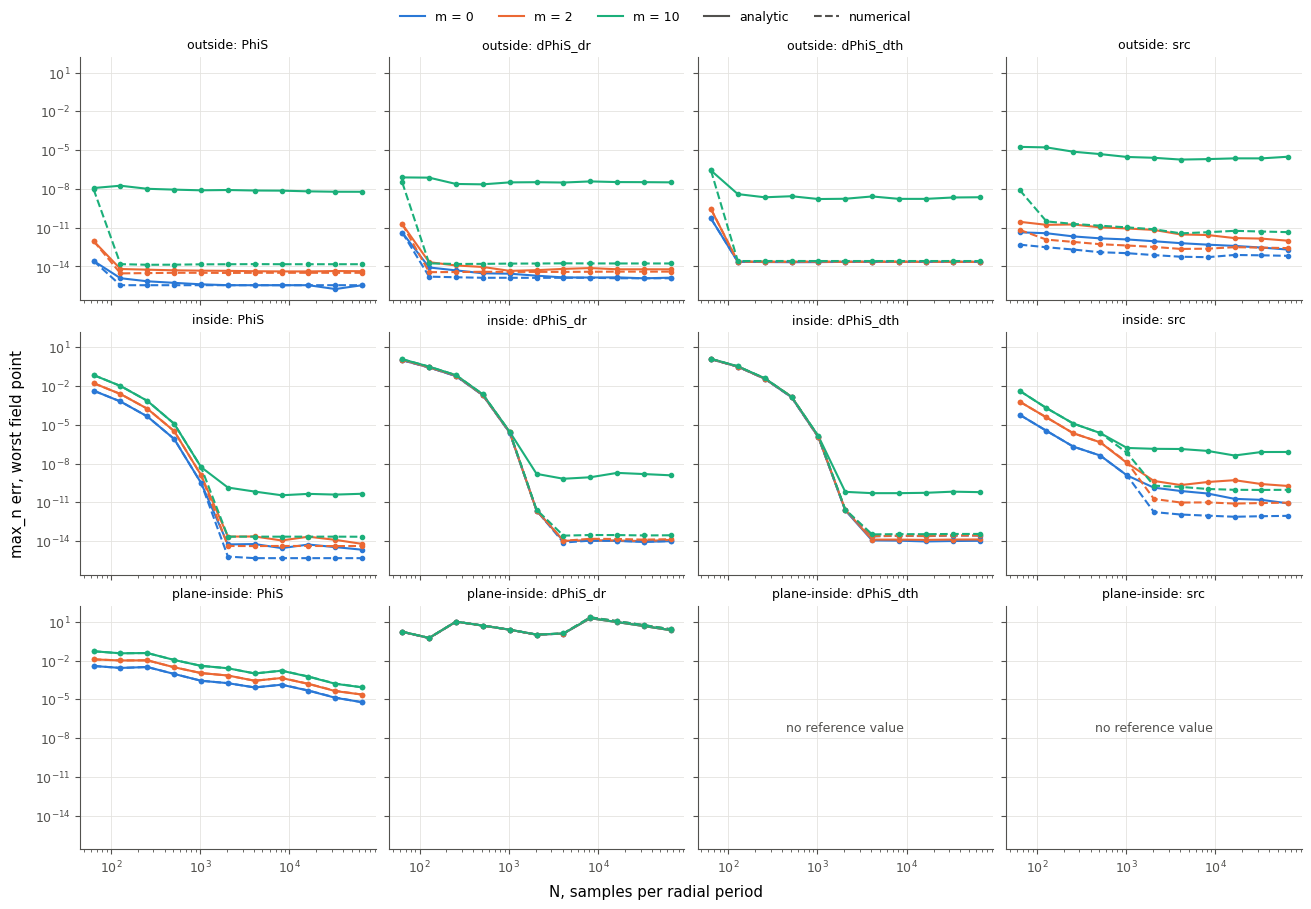

In [4]:
per_point = df.groupby(["label", "region", "route", "m", "quantity", "N"])["err"].max().reset_index()
worst = per_point.groupby(["region", "route", "m", "quantity", "N"])["err"].max().reset_index()

fig, axes = plt.subplots(3, 4, figsize=(13, 9), sharex=True, sharey=True, constrained_layout=True)
for i, reg in enumerate(REGIONS):
    for j, q in enumerate(QUANTITIES):
        ax = axes[i, j]
        sub = worst[(worst.region == reg) & (worst.quantity == q)]
        if sub.empty:
            empty(ax)
        for (route, m), g in sub.groupby(["route", "m"]):
            ax.loglog(g.N, g.err, STYLES[route], color=COLORS[m], marker="o")
        ax.set_title(f"{reg}: {q}", fontsize=9)
fig.supxlabel("N, samples per radial period")
fig.supylabel("max_n err, worst field point")
fig.legend(handles=legend_handles(), loc="outside upper center", ncol=5, frameon=False)
plt.show()

## Floors

For each field point, quantity, m and route: the floor (minimum over N of max_n err), the first N with max_n err ≤ 1e-10, and the first N within a factor 10 of the floor.

In [5]:
def summary(g):
    e = g.set_index("N")["err"]
    floor = e.min()
    return pd.Series({
        "floor": floor,
        "N(err<=1e-10)": e[e <= 1e-10].index.min(),
        "N(err<=10 floor)": e[e <= 10 * floor].index.min(),
    })

pd.set_option("display.max_rows", 600)
pd.set_option("display.float_format", lambda x: f"{x:.2e}")
table = per_point.groupby(["region", "label", "quantity", "m", "route"])[["N", "err"]].apply(summary)
table.unstack("route")

floor            \
route                                             analytic numerical   
region       label                   quantity  m                       
inside       r=11,dth=1/200          PhiS      0  3.37e-16  2.20e-16   
                                               2  4.27e-15  4.09e-15   
                                               10 5.33e-14  2.09e-14   
                                     dPhiS_dr  0  7.37e-15  6.85e-15   
                                               2  8.49e-15  9.19e-15   
                                               10 6.42e-14  2.54e-14   
                                     dPhiS_dth 0  8.63e-15  1.65e-14   
                                               2  1.18e-14  1.76e-14   
                                               10 2.88e-14  3.08e-14   
                                     src       0  5.09e-12  1.40e-13   
                                               2  4.82e-11  1.41e-12   
                                               10 1.10e-09  1.16e-11   
             r=11,dth=1/50           PhiS      0  1.73e-16  2.12e-16   
                                               2  4.19e-15  4.02e-15   
                                               10 4.13e-14  2.04e-14   
                                     dPhiS_dr  0  2.72e-15  3.07e-15   
                                               2  4.95e-15  5.11e-15   
                                               10 5.82e-14  2.05e-14   
                                     dPhiS_dth 0  3.69e-15  4.70e-15   
                                               2  6.16e-15  7.36e-15   
                                               10 2.29e-14  2.40e-14   
                                     src       0  4.45e-13  5.41e-13   
                                               2  9.04e-12  5.31e-12   
                                               10 5.95e-10  4.35e-11   
             r=11,dth=2/25           PhiS      0  1.14e-16  1.79e-16   
                                               2  4.08e-15  3.99e-15   
                                               10 8.57e-14  2.12e-14   
                                     dPhiS_dr  0  1.07e-15  1.32e-15   
                                               2  3.19e-15  3.38e-15   
                                               10 1.77e-13  1.86e-14   
                                     dPhiS_dth 0  1.01e-15  1.49e-15   
                                               2  4.22e-15  4.18e-15   
                                               10 2.43e-14  2.03e-14   
                                     src       0  2.03e-13  9.18e-14   
                                               2  1.17e-12  8.81e-13   
                                               10 4.85e-10  5.55e-12   
             r=11,dth=ArcSin[2/5]    PhiS      0  1.12e-16  1.12e-16   
                                               2  4.77e-15  3.84e-15   
                                               10 2.14e-11  1.99e-14   
                                     dPhiS_dr  0  4.05e-16  4.05e-16   
                                               2  2.16e-15  2.06e-15   
                                               10 3.24e-11  1.52e-14   
                                     dPhiS_dth 0  1.32e-16  1.31e-16   
                                               2  3.23e-15  3.97e-15   
                                               10 1.47e-11  1.98e-14   
                                     src       0  6.13e-15  2.30e-15   
                                               2  1.07e-13  3.01e-14   
                                               10 1.26e-09  1.71e-13   
             r=13,dth=1/200          PhiS      0  2.15e-15  1.79e-16   
                                               2  6.04e-15  2.97e-15   
                                               10 2.31e-13  1.76e-14   
                                     dPhiS_dr  0  7.52e-15  4.36e-15   
                                               2  7.64e-15  6.85e-15   
                     

## Error against n at the largest N

Three representative field points: outside the radial range, inside it close to the plane, and on the plane inside it.

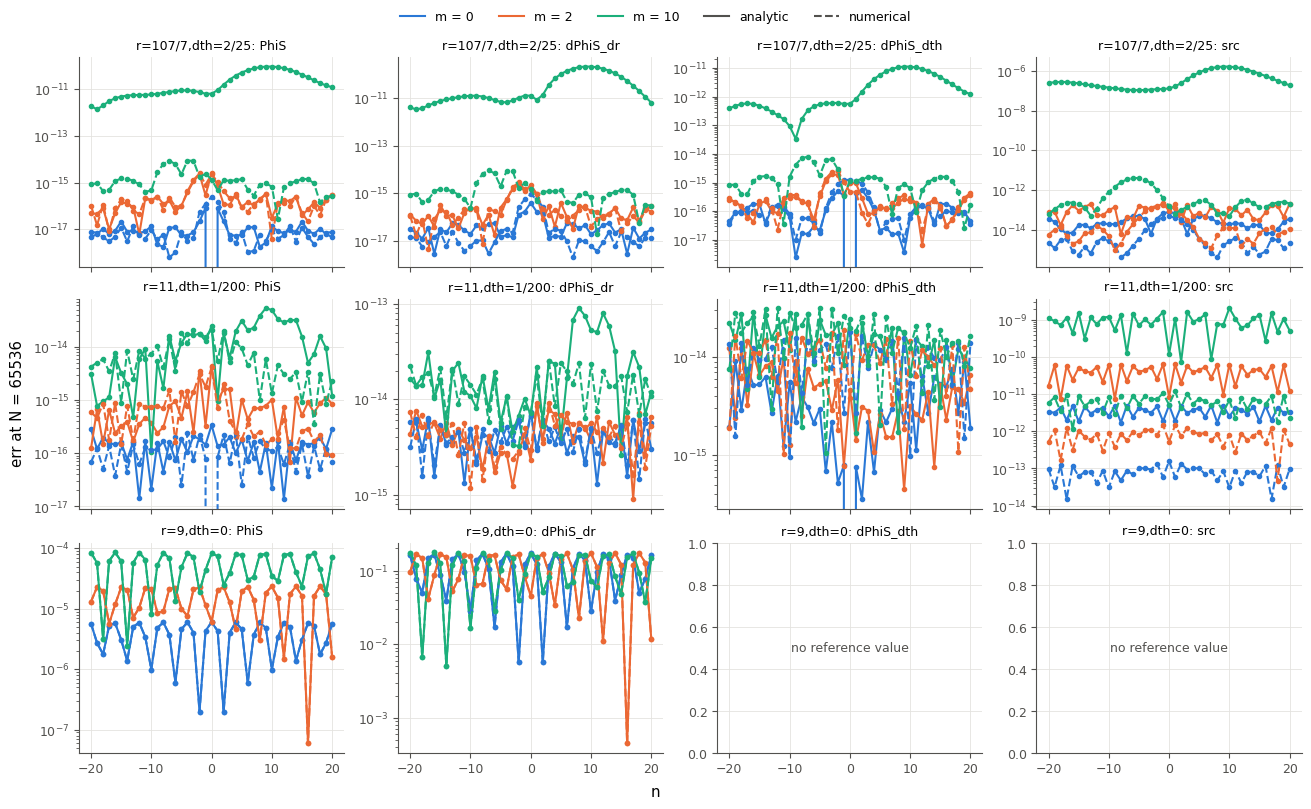

In [6]:
Nmax = df.N.max()
points = ["r=107/7,dth=2/25", "r=11,dth=1/200", "r=9,dth=0"]
fig, axes = plt.subplots(len(points), 4, figsize=(13, 8), sharex=True, constrained_layout=True)
for i, lab in enumerate(points):
    for j, q in enumerate(QUANTITIES):
        ax = axes[i, j]
        sub = df[(df.label == lab) & (df.N == Nmax) & (df.quantity == q)]
        if sub.empty:
            empty(ax)
        for (route, m), g in sub.groupby(["route", "m"]):
            ax.semilogy(g.n, g.err, STYLES[route], color=COLORS[m], marker="o")
        ax.set_title(f"{lab}: {q}", fontsize=9)
fig.supxlabel("n")
fig.supylabel(f"err at N = {Nmax}")
fig.legend(handles=legend_handles(), loc="outside upper center", ncol=5, frameon=False)
plt.show()

## Route numerical against route analytic

The difference |A_numerical − A_analytic| / max_n |A_ref|, maximised over n and over the field points of each region. It does not use the reference values, so it separates the error of the m-modes from that of the FFT over t.

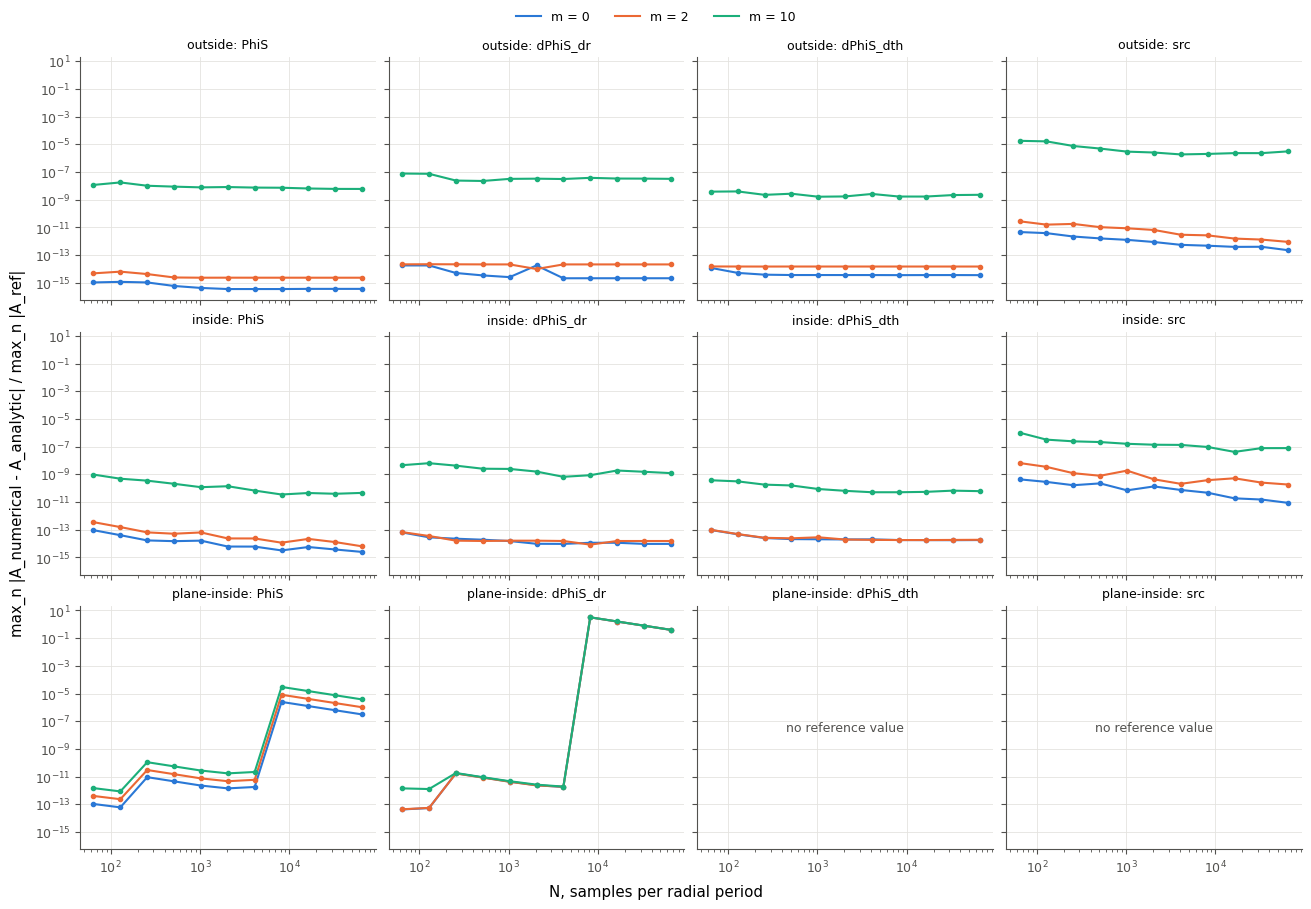

In [7]:
keys = ["label", "region", "m", "N", "quantity", "n"]
a = df[df.route == "analytic"].set_index(keys)
b = df[df.route == "numerical"].set_index(keys)
rel = (np.hypot(a["re"] - b["re"], a["im"] - b["im"]) / a["scale"]).rename("rel")
worst_diff = rel.groupby(level=["label", "region", "m", "N", "quantity"]).max().groupby(level=["region", "m", "N", "quantity"]).max().reset_index()

fig, axes = plt.subplots(3, 4, figsize=(13, 9), sharex=True, sharey=True, constrained_layout=True)
for i, reg in enumerate(REGIONS):
    for j, q in enumerate(QUANTITIES):
        ax = axes[i, j]
        sub = worst_diff[(worst_diff.region == reg) & (worst_diff.quantity == q)]
        if sub.empty:
            empty(ax)
        for m, g in sub.groupby("m"):
            ax.loglog(g.N, g.rel, color=COLORS[m], marker="o")
        ax.set_title(f"{reg}: {q}", fontsize=9)
fig.supxlabel("N, samples per radial period")
fig.supylabel("max_n |A_numerical - A_analytic| / max_n |A_ref|")
fig.legend(handles=legend_handles(routes=False), loc="outside upper center", ncol=3, frameon=False)
plt.show()

## Reality

The reference A_mn are real. The imaginary part of the C result, max_n |Im A_C| / max_n |A_ref|, maximised over the quantities and the field points of each region.

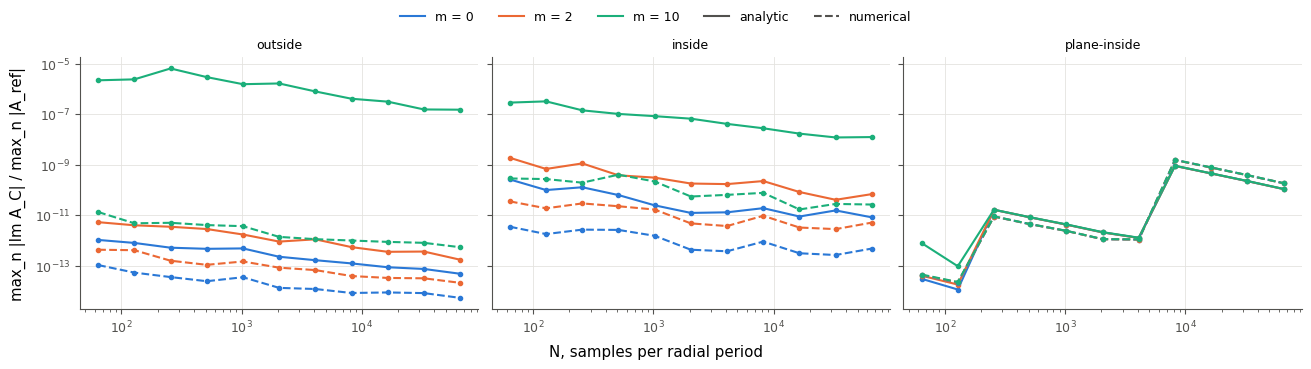

In [8]:
imag = df.assign(imr=np.abs(df["im"]) / df["scale"])
imag = imag.groupby(["region", "route", "m", "N"])["imr"].max().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True, constrained_layout=True)
for ax, reg in zip(axes, REGIONS):
    for (route, m), g in imag[imag.region == reg].groupby(["route", "m"]):
        ax.loglog(g.N, g.imr, STYLES[route], color=COLORS[m], marker="o")
    ax.set_title(reg, fontsize=9)
fig.supxlabel("N, samples per radial period")
fig.supylabel("max_n |Im A_C| / max_n |A_ref|")
fig.legend(handles=legend_handles(), loc="outside upper center", ncol=5, frameon=False)
plt.show()

## Findings

Measured on 2026-10-11 from 506 calls (23 field points, 2 routes, N = 2^6 … 2^16). No sample fell on the particle, no Newton solve reached 20 steps, and the largest residual |t(λ_j) − t_j| was 1.1 × 10⁻¹³, or 2 ulp(T_r). Route numerical capped N_φ at 2^20 for 34 samples, 14 at (9, 0) and 20 at (12, 0). The floors below are the minimum over N of max_n err, maximised over the field points of a region.

**Outside the radial range.**
- Route numerical is below 10⁻¹⁰ from N = 128 on for every quantity, with floors of at most 2.6 × 10⁻¹⁴ for PhiS, ∂_r and ∂_θ, and 5.2 × 10⁻¹⁴, 2.2 × 10⁻¹³ and 3.7 × 10⁻¹² for `src` at m = 0, 2 and 10.
- Route analytic matches it for m ∈ {0, 2} (at most 2.1 × 10⁻¹⁴, and 8.8 × 10⁻¹³ for `src`). At m = 10 its floors are 6.0 × 10⁻⁹ (PhiS), 2.3 × 10⁻⁸ (∂_r), 1.7 × 10⁻⁹ (∂_θ) and 1.6 × 10⁻⁶ (`src`), and all 9 outside points stay above 10⁻¹⁰ in `src`. The prediction of a floor between 10⁻¹⁵ and 10⁻¹³ holds for route numerical, except `src` at m = 2 and m = 10, and fails for route analytic at m = 10 and for its `src` at m = 0 and m = 2.

**Inside the radial range, off the plane.**
- Convergence starts once T_r/N resolves the peak. For route numerical at m = 2 the first N with max_n err ≤ 10⁻¹⁰ is 64 at Δθ = ArcSin[2/5], 128 to 256 at 2/25, 256 to 512 at 1/50 and 1024 to 2048 at 1/200, so it grows roughly in inverse proportion to Δθ, and Δθ = 1/200 converges last, as predicted.
- Floors of route numerical: at most 2.1 × 10⁻¹⁴ (PhiS), 2.5 × 10⁻¹⁴ (∂_r), 3.3 × 10⁻¹⁴ (∂_θ), and 7.6 × 10⁻¹³, 8.0 × 10⁻¹², 9.1 × 10⁻¹¹ for `src` at m = 0, 2, 10.
- Floors of route analytic: at most 1.2 × 10⁻¹⁴ for PhiS, ∂_r and ∂_θ at m ∈ {0, 2}, but 3.4 × 10⁻¹¹, 6.6 × 10⁻¹⁰ and 5.1 × 10⁻¹¹ at m = 10. For `src` they are 8.2 × 10⁻¹², 7.4 × 10⁻¹¹ and 4.2 × 10⁻⁸, and all 12 inside points stay above 10⁻¹⁰ in `src` at m = 10.
- The floor of 1.4 × 10⁻¹¹ that the spline-based FFT reached at (11, 1/50), m = 2, `src`, comes from the rounding of the analytic `calc_m` source: route analytic, which has no spline, reaches 1.40 × 10⁻¹¹ at N = 2^16, and route numerical 5.3 × 10⁻¹².

**On the plane inside the radial range.** Neither route converges cleanly, as predicted. PhiS falls slowly with N, to floors of 6.0 × 10⁻⁶ (m = 0), 2.4 × 10⁻⁵ (m = 2) and 8.6 × 10⁻⁵ (m = 10), and the worst max_n err of ∂_rPhiS lies between 0.57 and 23 at every N, with per-point floors of 0.026 to 0.18. The two routes agree to 1.1 × 10⁻¹⁰ or better up to N = 4096 and differ by up to O(1) in ∂_r above it. The capped samples start there: at N = 8192 for r = 12 and N = 16384 for r = 9.

**Route numerical against route analytic.** Route numerical is more accurate for `src` everywhere, as predicted: the largest floor is 3.7 × 10⁻¹² against 1.6 × 10⁻⁶ outside, and 9.1 × 10⁻¹¹ against 4.2 × 10⁻⁸ inside. It is also more accurate for PhiS and its derivatives at m = 10, by about five to six decades outside and three to four inside, which the spec did not predict.

**Reality.** At N = 2^16 the largest max_n |Im A_C| / max_n |A_ref| is 5.4 × 10⁻¹³ outside and 2.6 × 10⁻¹¹ inside for route numerical, against 1.5 × 10⁻⁷ and 1.2 × 10⁻⁸ for route analytic, both at m = 10.
